In [1]:

%pip install -q langchain-text-splitters pypdf openai tiktoken sentence-transformers matplotlib pandas python-dotenv

Note: you may need to restart the kernel to use updated packages.


In [8]:
import os
import shutil

os.environ["PATH"] = "/opt/homebrew/bin:" + os.environ["PATH"]

print(shutil.which("ffmpeg"))

/opt/homebrew/bin/ffmpeg


In [2]:
import os, re, json, statistics
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from pypdf import PdfReader

from langchain_text_splitters import (
    CharacterTextSplitter,
    RecursiveCharacterTextSplitter,
    TokenTextSplitter,
)

In [3]:
load_dotenv()   # reads the .env file

if os.getenv("OPENAI_API_KEY"):
    print("API key found")
else:
    print("No API key found. Check your .env file (it is needed for transcription).")

API key found


In [4]:
AUDIO_PATH = Path("The_Blueprint_For_Trustworthy_AI.m4a")

print("Current working folder:", Path.cwd())
if AUDIO_PATH.exists():
    print(f"Audio found: {AUDIO_PATH.name} ({AUDIO_PATH.stat().st_size / 1_000_000:.1f} MB)")
else:
    print("Audio NOT FOUND. Move the file into the folder shown above.")

Current working folder: /Users/jedrzej.czarnota/Desktop/AI/Week_3/Day_2/Lab_W3_D2/lab-chunking-strategies
Audio found: The_Blueprint_For_Trustworthy_AI.m4a (30.2 MB)


In [9]:
import subprocess, glob

TRANSCRIPT_PATH = Path("transcript.txt")

def transcribe_audio(audio_path, out_path, model="whisper-1", piece_seconds=600):
    """Transcribe audio with the OpenAI API and save the text. Skips all work if out_path already exists."""
    out = Path(out_path)
    if out.exists() and out.stat().st_size > 0:
        print(f"{out} already exists -> skipping transcription")
        return out.read_text(encoding="utf-8")

    # 1) shrink and cut the audio: mono, 64 kbps mp3, 10-minute pieces
    Path("_pieces").mkdir(exist_ok=True)
    subprocess.run(["ffmpeg", "-v", "error", "-y", "-i", str(audio_path), "-ac", "1", "-b:a", "64k",
                    "-f", "segment", "-segment_time", str(piece_seconds), "-reset_timestamps", "1",
                    "_pieces/piece_%02d.mp3"], check=True)

    # 2) transcribe the pieces in order
    from openai import OpenAI
    client = OpenAI()                                  # uses OPENAI_API_KEY from the environment
    texts = []
    for f in sorted(glob.glob("_pieces/piece_*.mp3")):
        with open(f, "rb") as fh:
            texts.append(client.audio.transcriptions.create(model=model, file=fh).text)
        print(f, "done")

    text = " ".join(texts)
    out.write_text(text, encoding="utf-8")             # save to a local file
    return text

podcast_text = transcribe_audio(AUDIO_PATH, TRANSCRIPT_PATH)
print(f"Podcast transcript length: {len(podcast_text)} chars")
print(podcast_text[:200])

_pieces/piece_00.mp3 done
_pieces/piece_01.mp3 done
Podcast transcript length: 16461 chars
So imagine for a second you're driving across, I don't know, a massive suspension bridge. OK. You don't pull over halfway across, get out and demand to see the blueprints, right? You don't interview t


In [6]:
import shutil
shutil.which("ffmpeg")

In [7]:
import os
import shutil

print("Python:", os.sys.executable)
print("PATH:", os.environ.get("PATH"))
print("ffmpeg:", repr(shutil.which("ffmpeg")))

Python: /opt/miniconda3/envs/bootcamp-env/bin/python
PATH: /opt/miniconda3/envs/bootcamp-env/bin:/opt/miniconda3/condabin:/Users/jedrzej.czarnota/.local/bin:/usr/local/bin:/System/Cryptexes/App/usr/bin:/usr/bin:/bin:/usr/sbin:/sbin:/var/run/com.apple.security.cryptexd/codex.system/bootstrap/usr/local/bin:/var/run/com.apple.security.cryptexd/codex.system/bootstrap/usr/bin:/var/run/com.apple.security.cryptexd/codex.system/bootstrap/usr/appleinternal/bin:/pkg/env/global/bin
ffmpeg: None


In [11]:
PDF_PATH = Path("ai_hleg_ethics_guidelines_for_trustworthy_ai-en.pdf")

def load_pdf(path=PDF_PATH):
    reader = PdfReader(path)
    return "\n".join(page.extract_text() or "" for page in reader.pages)

pdf_text = load_pdf()
print(f"PDF length: {len(pdf_text)} chars")
print(pdf_text[:200])

PDF length: 156411 chars
 
 
 
 
 
 
INDEPENDENT 
HIGH-LEVEL EXPERT GROUP ON 
ARTIFICIAL INTELLIGENCE 
SET UP BY THE EUROPEAN COMMISSION 
 
 
 
 
 
 
ETHICS GUIDELINES 
FOR TRUSTWORTHY AI 
 
 
 
 
 
 
ETHICS GUIDELINES FOR TR


In [12]:
splitter = CharacterTextSplitter(
    separator="",
    chunk_size=500,
    chunk_overlap=50,
    strip_whitespace=False
)

In [13]:
pdf_chunks = splitter.split_text(pdf_text)
podcast_chunks = splitter.split_text(podcast_text)

In [14]:
for i in range(3):
    print(f"--- Chunk {i} ending ---")
    print(repr(podcast_chunks[i][-50:]))

    print(f"--- Chunk {i + 1} beginning ---")
    print(repr(podcast_chunks[i + 1][:50]))
    print()

--- Chunk 0 ending ---
" Exactly. But now let's switch gears. Think about "
--- Chunk 1 beginning ---
" Exactly. But now let's switch gears. Think about "

--- Chunk 1 ending ---
' arguably the Magna Carta for ethical computing, t'
--- Chunk 2 beginning ---
' arguably the Magna Carta for ethical computing, t'

--- Chunk 2 ending ---
"cally the Stone Age. We didn't have the generative"
--- Chunk 3 beginning ---
"cally the Stone Age. We didn't have the generative"



In [15]:
print(repr(podcast_chunks[0][-80:]))
print(repr(podcast_chunks[1][50:130]))

"t's invisible, but it's there. Exactly. But now let's switch gears. Think about "
'the algorithm that just denied your mortgage application or the A.I. system scan'


In [16]:
def punctuation_report(chunks):
    endings = [chunk.rstrip()[-1] for chunk in chunks if chunk.strip()]
    clean = sum(char in ".?!" for char in endings)

    print(f"Total chunks: {len(chunks)}")
    print(f"Chunks ending with punctuation: {clean}")
    print(f"Percentage: {clean / len(chunks) * 100:.1f}%")

punctuation_report(podcast_chunks)
punctuation_report(pdf_chunks)

Total chunks: 37
Chunks ending with punctuation: 2
Percentage: 5.4%
Total chunks: 348
Chunks ending with punctuation: 11
Percentage: 3.2%


In [17]:
for chunk_size in [500, 1000, 2000]:
    for overlap in [0, 50, 100]:
        splitter = CharacterTextSplitter(
            separator="",
            chunk_size=chunk_size,
            chunk_overlap=overlap
        )

        chunks = splitter.split_text(podcast_text)
        endings = [chunk.rstrip()[-1] for chunk in chunks if chunk.strip()]
        clean = sum(char in ".?!" for char in endings)
        percentage = clean / len(chunks) * 100

        print(
            f"size={chunk_size}, overlap={overlap}: "
            f"{len(chunks)} chunks, {percentage:.1f}% ending cleanly"
        )

size=500, overlap=0: 33 chunks, 9.1% ending cleanly
size=500, overlap=50: 37 chunks, 5.4% ending cleanly
size=500, overlap=100: 41 chunks, 7.3% ending cleanly
size=1000, overlap=0: 17 chunks, 5.9% ending cleanly
size=1000, overlap=50: 18 chunks, 11.1% ending cleanly
size=1000, overlap=100: 19 chunks, 15.8% ending cleanly
size=2000, overlap=0: 9 chunks, 11.1% ending cleanly
size=2000, overlap=50: 9 chunks, 11.1% ending cleanly
size=2000, overlap=100: 9 chunks, 22.2% ending cleanly


In [18]:
def inspect_chunks(text, label, separator):
    splitter = CharacterTextSplitter(
        separator=separator,
        chunk_size=500,
        chunk_overlap=50
    )

    chunks = splitter.split_text(text)
    sizes = [len(chunk) for chunk in chunks]
    oversized = [size for size in sizes if size > 500]

    print(f"\n{label}")
    print(f"Number of chunks: {len(chunks)}")
    print(f"Average size: {sum(sizes) / len(sizes):.1f}")
    print(f"Minimum size: {min(sizes)}")
    print(f"Maximum size: {max(sizes)}")
    print(f"Chunks larger than 500 characters: {len(oversized)}")

    return chunks

In [19]:
print("Podcast has", podcast_text.count("\n\n"), "paragraph breaks")
print("PDF has", pdf_text.count("\n\n"), "paragraph breaks")

podcast_default = inspect_chunks(
    podcast_text,
    "Podcast with default separator",
    "\n\n"
)

podcast_fixed = inspect_chunks(
    podcast_text,
    "Podcast with separator=''",
    ""
)

pdf_default = inspect_chunks(
    pdf_text,
    "PDF with default separator",
    "\n\n"
)

pdf_fixed = inspect_chunks(
    pdf_text,
    "PDF with separator=''",
    ""
)

Created a chunk of size 28061, which is longer than the specified 500
Created a chunk of size 29967, which is longer than the specified 500
Created a chunk of size 23694, which is longer than the specified 500


Podcast has 0 paragraph breaks
PDF has 3 paragraph breaks

Podcast with default separator
Number of chunks: 1
Average size: 16461.0
Minimum size: 16461
Maximum size: 16461
Chunks larger than 500 characters: 1

Podcast with separator=''
Number of chunks: 37
Average size: 493.1
Minimum size: 261
Maximum size: 500
Chunks larger than 500 characters: 0

PDF with default separator
Number of chunks: 4
Average size: 39093.0
Minimum size: 23693
Maximum size: 74680
Chunks larger than 500 characters: 4

PDF with separator=''
Number of chunks: 348
Average size: 498.0
Minimum size: 258
Maximum size: 500
Chunks larger than 500 characters: 0


In [20]:
print(repr(podcast_default[0][-100:]))
print(repr(podcast_default[1][:100]))

"on't settle for the computer said so. Demand the blueprints. Until the next deep dive, stay curious."


IndexError: list index out of range

In [21]:
def show_boundaries(chunks, label, number_to_show=3):
    print(f"\n{label}")

    for i in range(min(number_to_show, len(chunks) - 1)):
        print(f"\nChunk {i} ending:")
        print(repr(chunks[i][-100:]))

        print(f"Chunk {i + 1} beginning:")
        print(repr(chunks[i + 1][:100]))

show_boundaries(podcast_fixed, "Podcast with separator=''")
show_boundaries(pdf_fixed, "PDF with separator=''")
show_boundaries(pdf_default, "PDF with default separator")


Podcast with separator=''

Chunk 0 ending:
"the infrastructure. It's invisible, but it's there. Exactly. But now let's switch gears. Think about"
Chunk 1 beginning:
"Exactly. But now let's switch gears. Think about the algorithm that just denied your mortgage applic"

Chunk 1 ending:
"for that trust. We're unpacking a document that is arguably the Magna Carta for ethical computing, t"
Chunk 2 beginning:
'arguably the Magna Carta for ethical computing, the ethics guidelines for trustworthy A.I. This is a'

Chunk 2 ending:
"public in April 2019. In tech years, that's practically the Stone Age. We didn't have the generative"
Chunk 3 beginning:
"cally the Stone Age. We didn't have the generative A.I. explosion we have today. So why are we blowi"

PDF with separator=''

Chunk 0 ending:
' document support the overall framework for Trustworthy AI put forward in these Guidelines, \nalthoug'
Chunk 1 beginning:
'orthy AI put forward in these Guidelines, \nalthough they do not necessarily agree 

In [22]:
def chunk_metrics(chunks):
    sizes = [len(chunk) for chunk in chunks]
    endings = [chunk.rstrip()[-1] for chunk in chunks if chunk.strip()]
    clean = sum(char in ".?!" for char in endings)

    return {
        "number of chunks": len(chunks),
        "average size": round(sum(sizes) / len(sizes), 1),
        "minimum size": min(sizes),
        "maximum size": max(sizes),
        "clean endings": clean,
        "clean ending %": round(clean / len(chunks) * 100, 1)
    }

comparison = pd.DataFrame({
    "Podcast": chunk_metrics(podcast_fixed),
    "PDF": chunk_metrics(pdf_fixed)
})

display(comparison)

,Podcast,PDF
number of chunks,37.0,348.0
average size,493.1,498.0
minimum size,261.0,258.0
maximum size,500.0,500.0
clean endings,2.0,11.0
clean ending %,5.4,3.2


Fixed-size chunking worked slightly better for the podcast transcript: 5.4% of its chunks ended with sentence punctuation, compared with 3.2% for the PDF. However, neither document aligned especially well with sentence boundaries. The podcast transcript is one long block with no paragraph breaks, so fixed-size chunking is relatively suitable, while the PDF contains more document structure that fixed-size chunking ignores.

In [23]:
splitter = TokenTextSplitter(encoding_name="cl100k_base", chunk_size=300, chunk_overlap=50)
pdf_token_chunks = splitter.split_text(pdf_text)
podcast_token_chunks = splitter.split_text(podcast_text)
print(len(pdf_token_chunks), "PDF chunks,", len(podcast_token_chunks), "podcast chunks")

127 PDF chunks, 14 podcast chunks


In [24]:
token_chunks = {}

for token_size in [500, 1000]:
    token_splitter = TokenTextSplitter(
        encoding_name="cl100k_base",
        chunk_size=token_size,
        chunk_overlap=50
    )

    token_chunks[token_size] = {
        "podcast": token_splitter.split_text(podcast_text),
        "pdf": token_splitter.split_text(pdf_text)
    }

    print(
        f"{token_size} tokens:",
        len(token_chunks[token_size]["podcast"]),
        "podcast chunks,",
        len(token_chunks[token_size]["pdf"]),
        "PDF chunks"
    )

500 tokens: 8 podcast chunks, 71 PDF chunks
1000 tokens: 4 podcast chunks, 34 PDF chunks


In [25]:
import tiktoken

encoding = tiktoken.get_encoding("cl100k_base")

character_chunks = {}

for chunk_size in [500, 1000]:
    char_splitter = CharacterTextSplitter(
        separator="",
        chunk_size=chunk_size,
        chunk_overlap=50
    )

    character_chunks[chunk_size] = {
        "podcast": char_splitter.split_text(podcast_text),
        "pdf": char_splitter.split_text(pdf_text)
    }

In [26]:
def summarize_chunks(chunks, document, method, target_size):
    char_sizes = [len(chunk) for chunk in chunks]
    token_sizes = [len(encoding.encode(chunk)) for chunk in chunks]

    return {
        "document": document,
        "method": method,
        "target size": target_size,
        "number of chunks": len(chunks),
        "average characters": round(sum(char_sizes) / len(char_sizes), 1),
        "average tokens": round(sum(token_sizes) / len(token_sizes), 1),
        "minimum tokens": min(token_sizes),
        "maximum tokens": max(token_sizes)
    }

rows = []

for size in [500, 1000]:
    for document in ["podcast", "pdf"]:
        rows.append(
            summarize_chunks(
                character_chunks[size][document],
                document,
                "characters",
                size
            )
        )

        rows.append(
            summarize_chunks(
                token_chunks[size][document],
                document,
                "tokens",
                size
            )
        )

comparison = pd.DataFrame(rows)
display(comparison)

,document,method,target size,number of chunks,average characters,average tokens,minimum tokens,maximum tokens
0,podcast,characters,500,37,493.1,106.3,63,123
1,podcast,tokens,500,8,2267.0,482.1,357,500
2,pdf,characters,500,348,498.0,102.1,65,162
3,pdf,tokens,500,71,2443.3,495.9,210,500
4,podcast,characters,1000,18,961.3,205.6,72,231
5,podcast,tokens,1000,4,4312.5,914.2,657,1000
6,pdf,characters,1000,165,995.4,202.9,156,293
7,pdf,tokens,1000,34,4836.4,981.1,360,1000


In [27]:
recursive_chunks = {}

recursive_splitter = RecursiveCharacterTextSplitter(
    chunk_size=1000,
    chunk_overlap=50
)

recursive_chunks[1000] = {
    "podcast": recursive_splitter.split_text(podcast_text),
    "pdf": recursive_splitter.split_text(pdf_text)
}

In [28]:
def chunk_stats(chunks):
    sizes = [len(chunk) for chunk in chunks]

    return {
        "Avg chunk size (chars)": round(sum(sizes) / len(sizes), 1),
        "Min": min(sizes),
        "Max": max(sizes),
        "# of chunks": len(sizes)
    }

rows = []

for document in ["podcast", "pdf"]:
    strategies = {
        "Fixed-500": character_chunks[500][document],
        "Recursive-1000": recursive_chunks[1000][document],
        "Token-500": token_chunks[500][document]
    }

    for strategy, chunks in strategies.items():
        row = {
            "Document": document,
            "Strategy": strategy
        }
        row.update(chunk_stats(chunks))
        rows.append(row)

comparison_table = pd.DataFrame(rows)
display(comparison_table)

,Document,Strategy,Avg chunk size (chars),Min,Max,# of chunks
0,podcast,Fixed-500,493.1,261,500,37
1,podcast,Recursive-1000,957.8,307,999,18
2,podcast,Token-500,2267.0,1569,2498,8
3,pdf,Fixed-500,498.0,258,500,348
4,pdf,Recursive-1000,932.2,232,998,168
5,pdf,Token-500,2443.3,748,2776,71


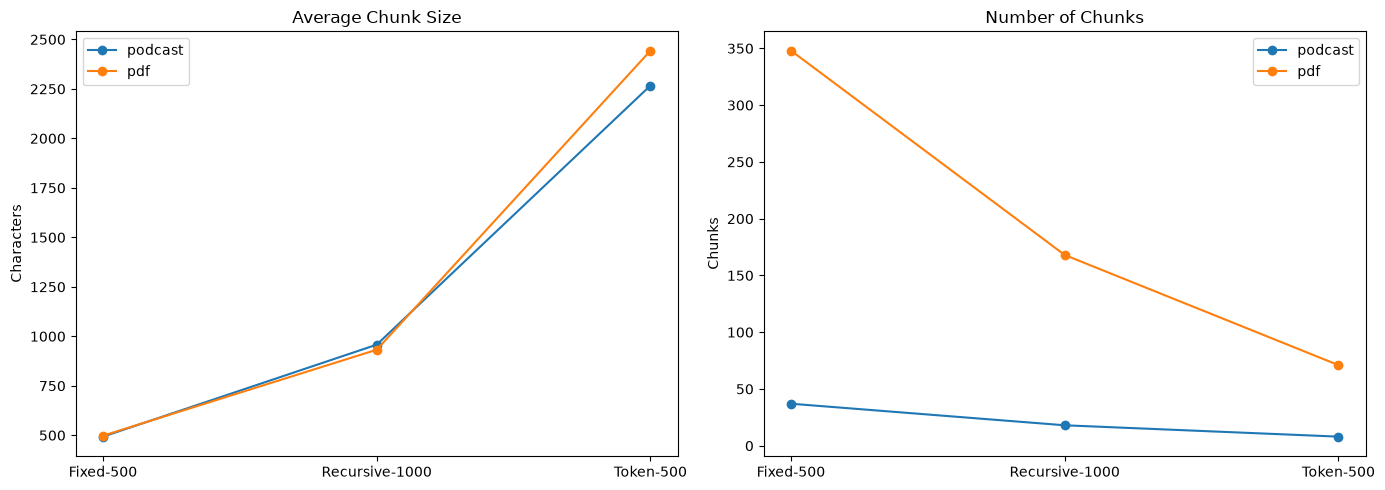

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for document in ["podcast", "pdf"]:
    data = comparison_table[comparison_table["Document"] == document]

    axes[0].plot(
        data["Strategy"],
        data["Avg chunk size (chars)"],
        marker="o",
        label=document
    )

    axes[1].plot(
        data["Strategy"],
        data["# of chunks"],
        marker="o",
        label=document
    )

axes[0].set_title("Average Chunk Size")
axes[0].set_ylabel("Characters")
axes[0].legend()

axes[1].set_title("Number of Chunks")
axes[1].set_ylabel("Chunks")
axes[1].legend()

plt.tight_layout()
plt.show()

### Chunking trade-offs

Fixed-size character chunking provides predictable character limits and is simple to implement, but it often cuts sentences in the middle. The 50-character overlap preserves some context between neighboring chunks, but it does not guarantee complete sentences.

Recursive chunking generally preserves paragraphs and other natural boundaries better than fixed-size chunking. Its chunks can vary in size, however, and very long paragraphs may still be split awkwardly.

Token-based chunking is the most useful when controlling an LLM's context window because each chunk contains a predictable number of tokens. Its character lengths vary considerably, and it requires the tokenizer associated with the model. Overall, token-based chunking offers the best control over model input size, while recursive chunking usually provides more readable semantic boundaries.

## Final comparison and recommendations

### Quantitative comparison

| Document | Strategy | Average chunk size (chars) | Minimum | Maximum | Number of chunks |
|---|---|---:|---:|---:|---:|
| Podcast | Fixed-500 | 493.1 | 261 | 500 | 37 |
| Podcast | Recursive-1000 | 957.8 | 307 | 999 | 18 |
| Podcast | Token-500 | 2267.0 | 1569 | 2498 | 8 |
| PDF | Fixed-500 | 498.0 | 258 | 500 | 348 |
| PDF | Recursive-1000 | 932.2 | 232 | 998 | 168 |
| PDF | Token-500 | 2443.3 | 748 | 2776 | 71 |

The character-based strategies produce chunks close to their character limits. Token-based chunks are much longer in characters because 500 tokens typically correspond to approximately 2,000–2,500 characters.

### Strategy trade-offs

| Strategy | Advantages | Limitations | Best use |
|---|---|---|---|
| Fixed-size character | Simple, predictable, and easy to calculate | Often cuts sentences and paragraphs in the middle | Baselines, simple text, or experiments |
| Recursive character | Usually preserves paragraphs and natural boundaries better | Chunk sizes vary; very long sections may still be split poorly | Readable documents and general-purpose retrieval |
| Token-based | Directly controls the model context window | Character lengths vary and tokenization may split words or subwords | LLM prompts, embeddings, and strict context limits |

### Recommendation for the podcast transcript

The podcast transcript contains no paragraph breaks, so fixed-size character chunking has little structure to preserve. Token-based chunking is a good choice when the chunks will be sent to an LLM because it gives direct control over the context size.

Recursive chunking can also work, especially with sentence-based separators, but the transcript's lack of paragraph structure limits its advantage. Fixed-size chunking is useful as a simple baseline but is less suitable for production retrieval.

### Recommendation for the PDF

The PDF contains more document structure, so recursive chunking is generally preferable when preserving readable sections and paragraphs is important. Custom separators could be used to prioritize headings, paragraphs, and sentences.

Token-based chunking is preferable when the PDF chunks will be inserted into an LLM context window or used for embeddings with strict token limits. Fixed-size character chunking is useful for comparison, but it is more likely to cut across meaningful document sections.

### Overall conclusion

There is no universally best chunking strategy. Fixed-size chunking is the simplest baseline, recursive chunking usually provides better semantic boundaries, and token-based chunking gives the most reliable control over LLM context size. The best choice depends on whether the priority is simplicity, readable boundaries, or precise token limits.